In [1]:
#1
!pip install PyWavelets tqdm librosa --quiet
print("Done!")

Done!


In [2]:
#2
import os, warnings, time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import soundfile as sf
import pywt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve
from scipy.optimize import brentq
from scipy.interpolate import interp1d
from scipy.fft import dct
import matplotlib.pyplot as plt
from tqdm import tqdm
import librosa

# ── FrFT: Fractional Fourier Transform ──────────────────────────
# Try the frft package first, fall back to chirp-modulation approx
try:
    from frft import frft as _ext_frft
    def compute_frft(signal, alpha):
        return _ext_frft(np.asarray(signal, dtype=complex), alpha)
    print("✓ frft package loaded")
except Exception:
    def compute_frft(signal, alpha):
        """
        FrFT via chirp modulation + FFT.
        alpha=0  → identity (time domain)
        alpha=1  → standard DFT (frequency domain)
        alpha=0.5 → 45° rotation (mixed view)
        Different alphas reveal different hidden patterns.
        """
        N   = len(signal)
        x   = np.asarray(signal, dtype=complex)
        if np.isclose(alpha % 2, 0): return x.copy()
        if np.isclose(alpha % 2, 1): return np.fft.fft(x) / np.sqrt(N)
        phi   = alpha * np.pi / 2
        n     = np.arange(N, dtype=float)
        chirp = np.exp(1j * np.pi * np.tan(phi / 2) * n**2 / N)
        return np.fft.fft(x * chirp) / np.sqrt(N)
    print("⚠  Using built-in FrFT (frft package unavailable)")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✓ Device: {device}")

⚠  Using built-in FrFT (frft package unavailable)
✓ Device: cuda


In [3]:
#3
# Quick directory structure check
BASE = '/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset'

key_paths = [
    'LA/LA/ASVspoof2019_LA_train/flac',
    'LA/LA/ASVspoof2019_LA_dev/flac',
    'LA/LA/ASVspoof2019_LA_eval/flac',
    'LA/LA/ASVspoof2019_LA_cm_protocols',
]

print("Dataset structure:")
for p in key_paths:
    full = os.path.join(BASE, p)
    if os.path.isdir(full):
        # Count files WITHOUT loading all names into memory
        count = sum(1 for _ in os.scandir(full))
        print(f"  ✓ {p}/  [{count:,} files]")
    else:
        print(f"  ✗ {p}/  [NOT FOUND]")

Dataset structure:
  ✓ LA/LA/ASVspoof2019_LA_train/flac/  [25,380 files]
  ✓ LA/LA/ASVspoof2019_LA_dev/flac/  [24,986 files]
  ✓ LA/LA/ASVspoof2019_LA_eval/flac/  [71,933 files]
  ✓ LA/LA/ASVspoof2019_LA_cm_protocols/  [3 files]


In [4]:
#4
# List protocol files + show sample audio filenames
BASE = '/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset'
LA   = BASE + '/LA/LA'

# Show protocol files
proto_dir = os.path.join(LA, 'ASVspoof2019_LA_cm_protocols')
print("Protocol files:")
for f in sorted(os.listdir(proto_dir)):
    size = os.path.getsize(os.path.join(proto_dir, f)) / 1024
    print(f"  {f}  ({size:.0f} KB)")

# Show 3 sample filenames from each audio split (not all 70K!)
print()
for split in ['train', 'dev', 'eval']:
    flac_dir = os.path.join(LA, f'ASVspoof2019_LA_{split}', 'flac')
    samples = []
    for i, entry in enumerate(os.scandir(flac_dir)):
        if i >= 3: break
        samples.append(entry.name)
    count = sum(1 for _ in os.scandir(flac_dir))
    print(f"{split} audio: {count:,} files  (e.g. {', '.join(samples)})")

Protocol files:
  ASVspoof2019.LA.cm.dev.trl.txt  (803 KB)
  ASVspoof2019.LA.cm.eval.trl.txt  (2303 KB)
  ASVspoof2019.LA.cm.train.trn.txt  (820 KB)

train audio: 25,380 files  (e.g. LA_T_9552332.flac, LA_T_2040122.flac, LA_T_5827423.flac)
dev audio: 24,986 files  (e.g. LA_D_5327408.flac, LA_D_8046653.flac, LA_D_4961527.flac)
eval audio: 71,933 files  (e.g. LA_E_3593759.flac, LA_E_9432034.flac, LA_E_1673131.flac)


In [5]:
#5
# ── Paths ────────────────────────────────────────────────────────
BASE = '/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset'
LA   = BASE + '/LA/LA'

PROTOCOLS   = LA + '/ASVspoof2019_LA_cm_protocols'
TRAIN_PROTO = PROTOCOLS + '/ASVspoof2019.LA.cm.train.trn.txt'
DEV_PROTO   = PROTOCOLS + '/ASVspoof2019.LA.cm.dev.trl.txt'
EVAL_PROTO  = PROTOCOLS + '/ASVspoof2019.LA.cm.eval.trl.txt'

TRAIN_AUDIO = LA + '/ASVspoof2019_LA_train/flac'
DEV_AUDIO   = LA + '/ASVspoof2019_LA_dev/flac'
EVAL_AUDIO  = LA + '/ASVspoof2019_LA_eval/flac'

# Verify every path exists
all_good = True
for label, path in [
    ('Train protocol', TRAIN_PROTO),
    ('Dev   protocol', DEV_PROTO),
    ('Eval  protocol', EVAL_PROTO),
    ('Train audio',    TRAIN_AUDIO),
    ('Dev   audio',    DEV_AUDIO),
    ('Eval  audio',    EVAL_AUDIO)
]:
    ok = os.path.exists(path)
    print(f"{'✓' if ok else '✗'}  {label}: {path}")
    if not ok:
        all_good = False

print()
if all_good:
    print("✓ All paths verified!")
else:
    print("✗ Some paths missing — check above")

# ── Feature parameters (IMPROVED) ───────────────────────────────
SR       = 16000                                        # sample rate
MAX_LEN  = 96000                                        # 6 seconds (was 4s)
ALPHAS   = [0.05, 0.15, 0.3, 0.5, 0.7, 0.85, 0.95]   # 7 FrFT angles (was 5)
WPD_LVL  = 5                                           # 32 sub-bands (was 16)
WAVELET  = 'db4'

# LFCC parameters (NEW)
N_LFCC        = 20
LFCC_N_FFT    = 512
LFCC_HOP      = 160
LFCC_N_FILTER = 128

# Feature dimensions
N_FRFT      = 7 * 8 * 8       # 7 angles × 8 chunks × 8 stats = 448
N_WPD       = 32 * 8          # 32 sub-bands × 8 stats = 256
N_LFCC_FEAT = 20 * 3 * 4      # 20 coeffs × 3 (static+Δ+ΔΔ) × 4 stats = 240
N_SPEC      = 52               # 6 scalar × 4 stats + 7 contrast × 4 stats
N_FEAT      = N_FRFT + N_WPD + N_LFCC_FEAT + N_SPEC  # 996

# ── Training parameters (IMPROVED) ──────────────────────────────
BATCH    = 128                # was 256
EPOCHS   = 60                 # was 25
LR       = 3e-4              # was 1e-3
SEED     = 42
PATIENCE = 10                 # early stopping (NEW)

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"\nDevice      : {device}")
print(f"Audio       : {MAX_LEN/SR:.1f}s ({MAX_LEN} samples)")
print(f"FrFT angles : {len(ALPHAS)} → {ALPHAS}")
print(f"WPD level   : {WPD_LVL} → {2**WPD_LVL} sub-bands")
print(f"\nFeature breakdown:")
print(f"  FrFT      : {N_FRFT}")
print(f"  WPD       : {N_WPD}")
print(f"  LFCC      : {N_LFCC_FEAT}")
print(f"  Spectral  : {N_SPEC}")
print(f"  TOTAL     : {N_FEAT}")
print(f"\nTraining: batch={BATCH}, epochs={EPOCHS}, lr={LR}, patience={PATIENCE}")

✓  Train protocol: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt
✓  Dev   protocol: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt
✓  Eval  protocol: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt
✓  Train audio: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac
✓  Dev   audio: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_dev/flac
✓  Eval  audio: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_eval/flac

✓ All paths verified!

Device      : cuda
Audio       : 6.0s (96000 samples)
FrFT angles : 7 → [0.05, 0.15, 0.3, 0.5, 0.7, 0.85, 0.95]
WPD level   : 5 → 32 sub-bands

Feature breakdown:
  FrFT      : 448
  WPD       : 256
  LFCC      : 240
  Spectral  : 52
  TOTAL     : 996

Training:

In [6]:
#6
def load_protocol(proto_path, audio_dir):
    """
    Parse ASVspoof 2019 LA protocol file.
    Format: speaker | file_id | env | attack_type | label
    Returns DataFrame with full audio path and binary label.
    1 = bonafide (real),  0 = spoof (fake)
    """
    df = pd.read_csv(
        proto_path, sep=' ', header=None,
        names=['speaker', 'file', 'env', 'attack', 'label']
    )
    df['binary'] = (df['label'] == 'bonafide').astype(int)
    df['path']   = df['file'].apply(
        lambda f: os.path.join(audio_dir, f + '.flac')
    )
    return df

train_df = load_protocol(TRAIN_PROTO, TRAIN_AUDIO)
dev_df   = load_protocol(DEV_PROTO,   DEV_AUDIO)
eval_df  = load_protocol(EVAL_PROTO,  EVAL_AUDIO)

print("Dataset split summary:")
print(f"{'Split':<8} {'Total':>8} {'Bonafide':>10} {'Spoof':>8}")
print("─" * 38)
for name, df in [('Train', train_df), ('Dev', dev_df), ('Eval', eval_df)]:
    n_real  = (df['binary'] == 1).sum()
    n_spoof = (df['binary'] == 0).sum()
    print(f"{name:<8} {len(df):>8,} {n_real:>10,} {n_spoof:>8,}")

print("\nSample rows from train_df:")
print(train_df[['file', 'attack', 'label', 'binary']].head(6).to_string(index=False))

# Verify at least one file actually exists on disk
sample_path = train_df.iloc[0]['path']
print(f"\nSample file exists: {os.path.exists(sample_path)}")
print(f"Sample path: {sample_path}")

Dataset split summary:
Split       Total   Bonafide    Spoof
──────────────────────────────────────
Train      25,380      2,580   22,800
Dev        24,844      2,548   22,296
Eval       71,237      7,355   63,882

Sample rows from train_df:
        file attack    label  binary
LA_T_1138215      - bonafide       1
LA_T_1271820      - bonafide       1
LA_T_1272637      - bonafide       1
LA_T_1276960      - bonafide       1
LA_T_1341447      - bonafide       1
LA_T_1363611      - bonafide       1

Sample file exists: True
Sample path: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1138215.flac


Real  file : LA_T_1138215  | attack: -
Spoof file : LA_T_1004644 | attack: A01


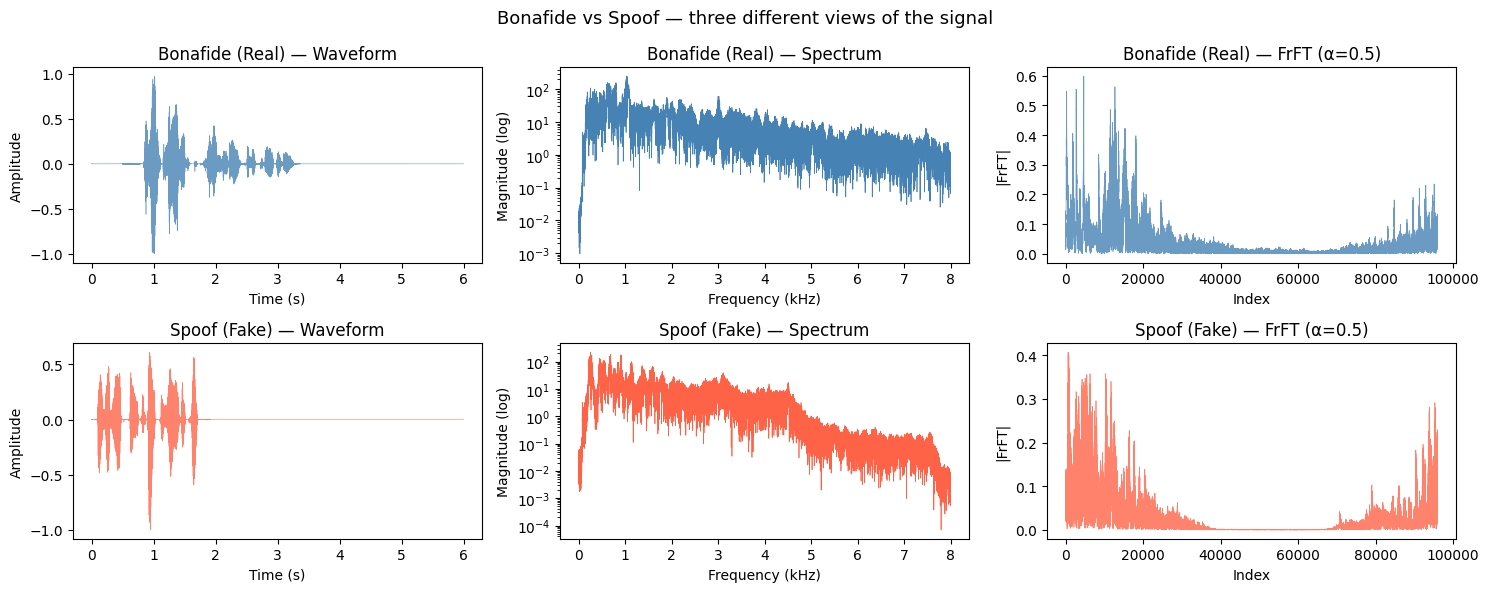

Saved → /kaggle/working/audio_visualization.png


In [7]:
#7
def load_audio(path, max_len=MAX_LEN):
    """
    Load a .flac file → mono float32 array of fixed length.
    Trims if too long, zero-pads if too short.
    """
    signal, _ = sf.read(path)
    if signal.ndim > 1:
        signal = signal.mean(axis=1)        # stereo → mono
    if len(signal) >= max_len:
        signal = signal[:max_len]
    else:
        signal = np.pad(signal, (0, max_len - len(signal)))
    return signal.astype(np.float32)

# Pick one real and one fake example from training set
real_row  = train_df[train_df['label'] == 'bonafide'].iloc[0]
spoof_row = train_df[train_df['label'] == 'spoof'].iloc[0]
real_sig  = load_audio(real_row['path'])
spoof_sig = load_audio(spoof_row['path'])

print(f"Real  file : {real_row['file']}  | attack: {real_row['attack']}")
print(f"Spoof file : {spoof_row['file']} | attack: {spoof_row['attack']}")

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
fig.suptitle('Bonafide vs Spoof — three different views of the signal', fontsize=13)

for i, (sig, title, color) in enumerate([
        (real_sig,  'Bonafide (Real)', 'steelblue'),
        (spoof_sig, 'Spoof (Fake)',    'tomato')]):

    t = np.arange(len(sig)) / SR

    # 1) Raw waveform — time domain
    axes[i][0].plot(t, sig, color=color, lw=0.4, alpha=0.8)
    axes[i][0].set_title(f'{title} — Waveform')
    axes[i][0].set_xlabel('Time (s)')
    axes[i][0].set_ylabel('Amplitude')

    # 2) Magnitude spectrum — frequency domain
    spec  = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), 1 / SR) / 1000
    axes[i][1].semilogy(freqs, spec + 1e-10, color=color, lw=0.5)
    axes[i][1].set_title(f'{title} — Spectrum')
    axes[i][1].set_xlabel('Frequency (kHz)')
    axes[i][1].set_ylabel('Magnitude (log)')

    # 3) FrFT at alpha=0.5 — the "in-between" time-frequency view
    frft_mag = np.abs(compute_frft(sig, 0.5))
    axes[i][2].plot(frft_mag, color=color, lw=0.5, alpha=0.8)
    axes[i][2].set_title(f'{title} — FrFT (α=0.5)')
    axes[i][2].set_xlabel('Index')
    axes[i][2].set_ylabel('|FrFT|')

plt.tight_layout()
plt.savefig('/kaggle/working/audio_visualization.png', dpi=120)
plt.show()
print("Saved → /kaggle/working/audio_visualization.png")

In [8]:
#8
# ═══════════════════════════════════════════════════════════════════
#  FEATURE ENGINEERING — the core novelty of this project
#  We extract features from 4 complementary "lenses":
#    1. FrFT  (Fractional Fourier Transform)  → 448 features
#    2. WPD   (Wavelet Packet Decomposition)  → 256 features
#    3. LFCC  (Linear Freq Cepstral Coeffs)   → 240 features (NEW)
#    4. Spectral statistics                    →  52 features (NEW)
#  Total: 996 features per audio clip
# ═══════════════════════════════════════════════════════════════════

# ── Helper: 8 statistics from an array ───────────────────────────
def stats8(arr):
    """Compute 8 statistical descriptors from an array."""
    arr  = np.abs(arr).astype(np.float64) + 1e-10
    p    = arr / arr.sum()
    return np.array([
        arr.mean(), arr.std(), arr.max(), arr.min(),
        np.percentile(arr, 25), np.percentile(arr, 75),
        np.sum(arr**2),                    # energy
        -np.sum(p * np.log(p + 1e-10))    # entropy
    ], dtype=np.float32)

# ── Helper: frame-level statistics ───────────────────────────────
def frame_stats4(matrix):
    """
    For a (n_features, n_frames) matrix, compute 4 stats across
    frames for each feature: mean, std, max, min.
    Returns array of shape (n_features * 4,).
    """
    if matrix.ndim == 1:
        matrix = matrix.reshape(1, -1)
    return np.concatenate([
        matrix.mean(axis=1),
        matrix.std(axis=1),
        matrix.max(axis=1),
        matrix.min(axis=1)
    ]).astype(np.float32)

# ── Linear filterbank for LFCC (cached) ──────────────────────────
_LINEAR_FBANK = None

def _get_linear_filterbank(sr, n_fft, n_filter, n_freq_bins):
    """Create and cache a triangular linear filterbank."""
    global _LINEAR_FBANK
    if _LINEAR_FBANK is not None and _LINEAR_FBANK.shape == (n_filter, n_freq_bins):
        return _LINEAR_FBANK

    freqs         = np.linspace(0, sr / 2, n_freq_bins)
    filter_points = np.linspace(0, sr / 2, n_filter + 2)
    fbank         = np.zeros((n_filter, n_freq_bins))

    for i in range(n_filter):
        f_lo  = filter_points[i]
        f_mid = filter_points[i + 1]
        f_hi  = filter_points[i + 2]
        # Rising slope
        up = (freqs >= f_lo) & (freqs <= f_mid)
        if f_mid > f_lo:
            fbank[i, up] = (freqs[up] - f_lo) / (f_mid - f_lo)
        # Falling slope
        dn = (freqs > f_mid) & (freqs <= f_hi)
        if f_hi > f_mid:
            fbank[i, dn] = (f_hi - freqs[dn]) / (f_hi - f_mid)

    _LINEAR_FBANK = fbank
    return fbank

# ── Lens 1: FrFT features ───────────────────────────────────────
def extract_frft_features(signal, alphas=ALPHAS):
    """
    Fractional Fourier Transform at multiple angles.
    For each angle: compute FrFT magnitude → split into 8 chunks → stats8 each.
    Returns: 7 angles × 8 chunks × 8 stats = 448 features.
    """
    feats = []
    for alpha in alphas:
        transformed = compute_frft(signal.astype(complex), alpha)
        mag = np.abs(transformed)
        chunks = np.array_split(mag, 8)
        for chunk in chunks:
            feats.append(stats8(chunk))
    return np.concatenate(feats)

# ── Lens 2: WPD features ────────────────────────────────────────
def extract_wpd_features(signal, wavelet=WAVELET, level=WPD_LVL):
    """
    Wavelet Packet Decomposition at level 5 → 32 sub-bands.
    Returns: 32 bands × 8 stats = 256 features.
    """
    wp    = pywt.WaveletPacket(data=signal, wavelet=wavelet,
                               mode='symmetric', maxlevel=level)
    nodes = wp.get_level(level, 'natural')
    feats = [stats8(node.data) for node in nodes]
    return np.concatenate(feats)

# ── Lens 3: LFCC features (NEW) ─────────────────────────────────
def extract_lfcc_features(signal, sr=SR):
    """
    Linear Frequency Cepstral Coefficients with delta and delta-delta.
    Unlike MFCC (mel filterbank), LFCC uses a LINEAR filterbank.
    This is better for detecting vocoder artifacts across ALL frequencies.

    Returns: 20 coeffs × 3 (static+Δ+ΔΔ) × 4 stats = 240 features.
    """
    # Step 1: Power spectrogram
    S = np.abs(librosa.stft(signal, n_fft=LFCC_N_FFT, hop_length=LFCC_HOP))**2
    n_freq_bins = S.shape[0]

    # Step 2: Apply linear filterbank → log power
    fbank    = _get_linear_filterbank(sr, LFCC_N_FFT, LFCC_N_FILTER, n_freq_bins)
    filtered = np.dot(fbank, S)
    log_pow  = np.log(filtered + 1e-10)

    # Step 3: DCT → cepstral coefficients (keep first N_LFCC)
    lfcc = dct(log_pow, type=2, axis=0, norm='ortho')[:N_LFCC]  # (20, n_frames)

    # Edge case: if audio is very short, pad to at least 3 frames
    if lfcc.shape[1] < 3:
        lfcc = np.pad(lfcc, ((0, 0), (0, 3 - lfcc.shape[1])), mode='constant')

    # Step 4: Delta and delta-delta (velocity and acceleration)
    delta  = librosa.feature.delta(lfcc, width=3)
    delta2 = librosa.feature.delta(lfcc, order=2, width=3)

    # Step 5: Stack and compute frame-level stats
    stacked = np.vstack([lfcc, delta, delta2])   # (60, n_frames)
    return frame_stats4(stacked)                  # 60 × 4 = 240

# ── Lens 4: Spectral features (NEW) ─────────────────────────────
def extract_spectral_features(signal, sr=SR):
    """
    Classic spectral descriptors computed frame-wise, then summarized.
    Returns: 6 scalar features × 4 stats + 7 contrast bands × 4 stats = 52.
    """
    # 6 scalar spectral features (each shape: 1×n_frames)
    cent     = librosa.feature.spectral_centroid(y=signal, sr=sr)
    bw       = librosa.feature.spectral_bandwidth(y=signal, sr=sr)
    rolloff  = librosa.feature.spectral_rolloff(y=signal, sr=sr)
    flatness = librosa.feature.spectral_flatness(y=signal)
    zcr      = librosa.feature.zero_crossing_rate(signal)
    rms      = librosa.feature.rms(y=signal)

    scalars  = np.vstack([cent, bw, rolloff, flatness, zcr, rms])  # (6, n_frames)
    s_feats  = frame_stats4(scalars)                                # 6×4 = 24

    # Spectral contrast: 7 bands per frame
    contrast = librosa.feature.spectral_contrast(y=signal, sr=sr)  # (7, n_frames)
    c_feats  = frame_stats4(contrast)                               # 7×4 = 28

    return np.concatenate([s_feats, c_feats])  # 52

# ── Combined extraction ──────────────────────────────────────────
def extract_features(signal):
    """
    Full feature extraction pipeline.
    Order: FrFT(448) | WPD(256) | LFCC(240) | Spectral(52) = 996
    """
    frft_feats = extract_frft_features(signal)      # 448
    wpd_feats  = extract_wpd_features(signal)       # 256
    lfcc_feats = extract_lfcc_features(signal)      # 240
    spec_feats = extract_spectral_features(signal)  # 52

    combined = np.concatenate([frft_feats, wpd_feats, lfcc_feats, spec_feats])

    # Safety: replace any NaN/Inf with 0
    combined = np.nan_to_num(combined, nan=0.0, posinf=0.0, neginf=0.0)
    return combined.astype(np.float32)

# ── Sanity check ─────────────────────────────────────────────────
test = extract_features(real_sig)
print(f"Feature vector size: {test.shape}")    # should be (996,)
print(f"Any NaN/Inf: {np.any(~np.isfinite(test))}")
assert test.shape == (N_FEAT,), f"Expected ({N_FEAT},), got {test.shape}"
print("✓ Feature engineering ready!")

Feature vector size: (996,)
Any NaN/Inf: False
✓ Feature engineering ready!


In [9]:
#9
FEAT_DIR = '/kaggle/working/features_v2'
os.makedirs(FEAT_DIR, exist_ok=True)

def process_split(df, split_name):
    """
    Extract and cache features for one split.
    First run: slow (extracts from audio files).
    All later runs: instant (loads from .npy cache).
    """
    path_X = os.path.join(FEAT_DIR, f'{split_name}_X.npy')
    path_y = os.path.join(FEAT_DIR, f'{split_name}_y.npy')

    # Load from cache if already processed AND correct shape
    if os.path.exists(path_X) and os.path.exists(path_y):
        X = np.load(path_X)
        y = np.load(path_y)
        if X.shape[1] == N_FEAT:
            print(f"[{split_name}] Loaded from cache → X:{X.shape}  y:{y.shape}")
            return X, y
        else:
            print(f"[{split_name}] Cache shape {X.shape[1]} != {N_FEAT}, re-extracting...")
            os.remove(path_X)
            os.remove(path_y)

    print(f"[{split_name}] Extracting features for {len(df):,} files...")
    X, y    = [], []
    skipped = 0

    for _, row in tqdm(df.iterrows(), total=len(df), desc=split_name):
        try:
            signal = load_audio(row['path'])
            X.append(extract_features(signal))
            y.append(row['binary'])
        except Exception as e:
            skipped += 1

    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.int64)

    np.save(path_X, X)
    np.save(path_y, y)
    print(f"[{split_name}] Done — X:{X.shape}  y:{y.shape}  skipped:{skipped}  ✓ cached")
    return X, y

t0 = time.time()
print("=" * 60)
print("  FEATURE EXTRACTION (v2) — this runs once and caches.")
print("  Train: ~30 min | Dev: ~30 min | Eval: ~80 min")
print("  Do NOT close this tab while running.")
print("=" * 60 + "\n")

X_train, y_train = process_split(train_df, 'train')
X_dev,   y_dev   = process_split(dev_df,   'dev')
X_eval,  y_eval  = process_split(eval_df,  'eval')

elapsed = (time.time() - t0) / 60
print(f"\n{'=' * 60}")
print(f"  All done in {elapsed:.1f} min")
print(f"  X_train : {X_train.shape}")
print(f"  X_dev   : {X_dev.shape}")
print(f"  X_eval  : {X_eval.shape}")
print(f"{'=' * 60}")

  FEATURE EXTRACTION (v2) — this runs once and caches.
  Train: ~30 min | Dev: ~30 min | Eval: ~80 min
  Do NOT close this tab while running.

[train] Extracting features for 25,380 files...


train: 100%|██████████| 25380/25380 [1:20:53<00:00,  5.23it/s]


[train] Done — X:(25380, 996)  y:(25380,)  skipped:0  ✓ cached
[dev] Extracting features for 24,844 files...


dev: 100%|██████████| 24844/24844 [1:20:30<00:00,  5.14it/s]


[dev] Done — X:(24844, 996)  y:(24844,)  skipped:0  ✓ cached
[eval] Extracting features for 71,237 files...


eval: 100%|██████████| 71237/71237 [3:52:44<00:00,  5.10it/s]  


[eval] Done — X:(71237, 996)  y:(71237,)  skipped:0  ✓ cached

  All done in 394.1 min
  X_train : (25380, 996)
  X_dev   : (24844, 996)
  X_eval  : (71237, 996)


In [10]:
#10
# StandardScaler: fit ONLY on training data, apply to dev + eval
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_dev_sc   = scaler.transform(X_dev)
X_eval_sc  = scaler.transform(X_eval)

class AudioDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.X[i], self.y[i]

train_ds = AudioDataset(X_train_sc, y_train)
dev_ds   = AudioDataset(X_dev_sc,   y_dev)
eval_ds  = AudioDataset(X_eval_sc,  y_eval)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
dev_loader   = DataLoader(dev_ds,   batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)
eval_loader  = DataLoader(eval_ds,  batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)

# Class weights — bonafide is minority, give it more weight
n_total = len(y_train)
n_real  = int(y_train.sum())
n_spoof = n_total - n_real

class_weight = torch.tensor([
    n_total / (2.0 * n_spoof),   # weight for class 0 (spoof)
    n_total / (2.0 * n_real)     # weight for class 1 (bonafide)
], dtype=torch.float32).to(device)

print(f"Train bonafide : {n_real:,}")
print(f"Train spoof    : {n_spoof:,}")
print(f"Class weights  → spoof: {class_weight[0]:.3f} | bonafide: {class_weight[1]:.3f}")
print(f"Train batches  : {len(train_loader)}")
print(f"\nDatasets ready!")

Train bonafide : 2,580
Train spoof    : 22,800
Class weights  → spoof: 0.557 | bonafide: 4.919
Train batches  : 198

Datasets ready!


In [ ]:
#11
# ═══════════════════════════════════════════════════════════════════
#  LCNN with residual connection + Focal Loss + Mixup
#  ~725K params (was 70K) — still lightweight, much more capable
# ═══════════════════════════════════════════════════════════════════

class MFM(nn.Module):
    """
    Max Feature Map activation — the core building block of LCNN.
    Input: (batch, 2n) → Output: (batch, n)
    Keeps the max of each pair of competing neurons.
    """
    def forward(self, x):
        n = x.shape[1] // 2
        return torch.max(x[:, :n], x[:, n:])


class LCNN(nn.Module):
    """
    Light CNN for deepfake audio detection.
    
    Architecture:
      Input(996) → FC(512) → MFM→256 → BN → Drop(0.4)
                 → FC(512) → MFM→256 → BN → Drop(0.3) + RESIDUAL
                 → FC(256) → MFM→128 → BN → Drop(0.25)
                 → FC(128) → MFM→64  → BN → Drop(0.2)
                 → FC(2)   → logits

    Block 2 has a residual connection (input dim = output dim = 256).
    """
    def __init__(self, input_dim):
        super().__init__()

        # Block 1: input → 512 → MFM → 256
        self.block1 = nn.Sequential(
            nn.Linear(input_dim, 512), MFM(),
            nn.BatchNorm1d(256), nn.Dropout(0.4)
        )
        # Block 2: 256 → 512 → MFM → 256 (same dim → residual!)
        self.fc2   = nn.Linear(256, 512)
        self.mfm2  = MFM()
        self.bn2   = nn.BatchNorm1d(256)
        self.drop2 = nn.Dropout(0.3)

        # Block 3: 256 → 256 → MFM → 128
        self.block3 = nn.Sequential(
            nn.Linear(256, 256), MFM(),
            nn.BatchNorm1d(128), nn.Dropout(0.25)
        )
        # Block 4: 128 → 128 → MFM → 64
        self.block4 = nn.Sequential(
            nn.Linear(128, 128), MFM(),
            nn.BatchNorm1d(64), nn.Dropout(0.2)
        )
        self.classifier = nn.Linear(64, 2)

        # Kaiming initialization — better for MFM activations
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.block1(x)
        # Block 2 with residual
        identity = x
        x = self.drop2(self.bn2(self.mfm2(self.fc2(x))))
        x = x + identity                  # skip connection
        x = self.block3(x)
        x = self.block4(x)
        return self.classifier(x)


class FocalLoss(nn.Module):
    """
    Focal Loss: down-weights easy examples, focuses on hard ones.
    Much better than CrossEntropy for imbalanced datasets.
    gamma=2 is the standard choice.
    """
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()


def mixup_data(x, y, alpha=0.2):
    """Mixup augmentation: blend pairs of samples for regularization."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0)).to(x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    """Loss for mixup-augmented batch."""
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


model       = LCNN(input_dim=N_FEAT).to(device)
total_params = sum(p.numel() for p in model.parameters())

print(model)
print(f"\nTotal trainable parameters: {total_params:,}")
print(f"Input dimension: {N_FEAT} features")
print(f"Output: 2 classes (spoof=0, bonafide=1)")

LCNN(
  (block1): Sequential(
    (0): Linear(in_features=996, out_features=512, bias=True)
    (1): MFM()
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
  )
  (fc2): Linear(in_features=256, out_features=512, bias=True)
  (mfm2): MFM()
  (bn2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (drop2): Dropout(p=0.3, inplace=False)
  (block3): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): MFM()
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.25, inplace=False)
  )
  (block4): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): MFM()
    (2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.2, inplace=False)
  )
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)

Total trainabl

In [ ]:
#12
# ═══════════════════════════════════════════════════════════════════
#  Training with: Focal Loss, Mixup, OneCycleLR, Gradient Clipping,
#  Early Stopping — all improvements combined
# ═══════════════════════════════════════════════════════════════════

def compute_eer(labels, scores):
    """Equal Error Rate: point where FAR == FRR. Lower = better."""
    fpr, tpr, _ = roc_curve(labels, scores, pos_label=1)
    fnr         = 1 - tpr
    idx         = np.nanargmin(np.abs(fnr - fpr))
    return float(np.mean([fpr[idx], fnr[idx]])) * 100

def evaluate(mdl, loader):
    """Return EER (%) and accuracy (%) on a given data loader."""
    mdl.eval()
    all_labels, all_scores = [], []
    correct = 0

    with torch.no_grad():
        for X, y in loader:
            X, y    = X.to(device), y.to(device)
            logits  = mdl(X)
            probs   = torch.softmax(logits, dim=1)[:, 1]  # P(bonafide)
            correct += (logits.argmax(1) == y).sum().item()
            all_labels.extend(y.cpu().numpy())
            all_scores.extend(probs.cpu().numpy())

    acc = 100.0 * correct / len(all_labels)
    eer = compute_eer(np.array(all_labels), np.array(all_scores))
    return eer, acc

# ── Setup ────────────────────────────────────────────────────────
criterion = FocalLoss(alpha=class_weight, gamma=2.0)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR,
    epochs=EPOCHS, steps_per_epoch=len(train_loader),
    pct_start=0.1, anneal_strategy='cos'
)

history          = {'loss': [], 'dev_eer': [], 'dev_acc': []}
best_dev_eer     = float('inf')
best_epoch       = 0
patience_counter = 0

print(f"Training LCNN for up to {EPOCHS} epochs on {device}")
print(f"Early stopping patience: {PATIENCE} epochs")
print(f"{'Epoch':>6} | {'Loss':>8} | {'Dev EER':>9} | {'Dev Acc':>8} | {'LR':>10} | {'Time':>6}")
print("─" * 62)

for ep in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    t0         = time.time()

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        # Mixup augmentation
        mixed_x, y_a, y_b, lam = mixup_data(X, y, alpha=0.2)

        # Forward + loss
        logits = model(mixed_x)
        loss   = mixup_criterion(criterion, logits, y_a, y_b, lam)

        # Backward + gradient clipping
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        scheduler.step()   # OneCycleLR steps per batch

        total_loss += loss.item()

    avg_loss         = total_loss / len(train_loader)
    dev_eer, dev_acc = evaluate(model, dev_loader)
    elapsed          = time.time() - t0
    current_lr       = optimizer.param_groups[0]['lr']

    history['loss'].append(avg_loss)
    history['dev_eer'].append(dev_eer)
    history['dev_acc'].append(dev_acc)

    flag = ''
    if dev_eer < best_dev_eer:
        best_dev_eer     = dev_eer
        best_epoch       = ep
        patience_counter = 0
        flag             = '  ← best'
        torch.save(model.state_dict(), '/kaggle/working/best_lcnn_v2.pt')
    else:
        patience_counter += 1

    print(f"{ep:>6} | {avg_loss:>8.4f} | {dev_eer:>8.2f}% | {dev_acc:>7.2f}% | {current_lr:>10.2e} | {elapsed:>5.1f}s{flag}")

    if patience_counter >= PATIENCE:
        print(f"\n⚡ Early stopping at epoch {ep} — no improvement for {PATIENCE} epochs")
        break

print(f"\n✓ Best Dev EER : {best_dev_eer:.2f}% at epoch {best_epoch}")
print("✓ Model saved  → /kaggle/working/best_lcnn_v2.pt")

Training LCNN for up to 60 epochs on cuda
Early stopping patience: 10 epochs
 Epoch |     Loss |   Dev EER |  Dev Acc |         LR |   Time
──────────────────────────────────────────────────────────────
     1 |   0.5685 |    23.85% |   45.06% |   3.13e-05 |   3.6s  ← best
     2 |   0.3349 |    10.08% |   58.88% |   8.41e-05 |   2.4s  ← best
     3 |   0.2115 |     5.61% |   69.20% |   1.56e-04 |   2.4s  ← best
     4 |   0.1507 |     2.60% |   82.92% |   2.28e-04 |   2.5s  ← best
     5 |   0.1093 |     2.24% |   88.70% |   2.81e-04 |   2.4s  ← best
     6 |   0.0924 |     1.36% |   89.71% |   3.00e-04 |   2.5s  ← best
     7 |   0.0826 |     1.16% |   90.70% |   3.00e-04 |   2.4s  ← best
     8 |   0.0889 |     0.86% |   92.62% |   2.99e-04 |   2.5s  ← best
     9 |   0.0714 |     0.86% |   92.88% |   2.98e-04 |   2.5s  ← best
    10 |   0.0718 |     0.70% |   94.13% |   2.96e-04 |   2.5s  ← best
    11 |   0.0783 |     0.75% |   92.54% |   2.94e-04 |   2.4s
    12 |   0.0637 |     

  EVAL SET RESULTS (ASVspoof 2019 LA)
  EVAL EER      : 13.55%
  EVAL ACCURACY : 40.27%
  (Lower EER = better. Previous: 11.79%)


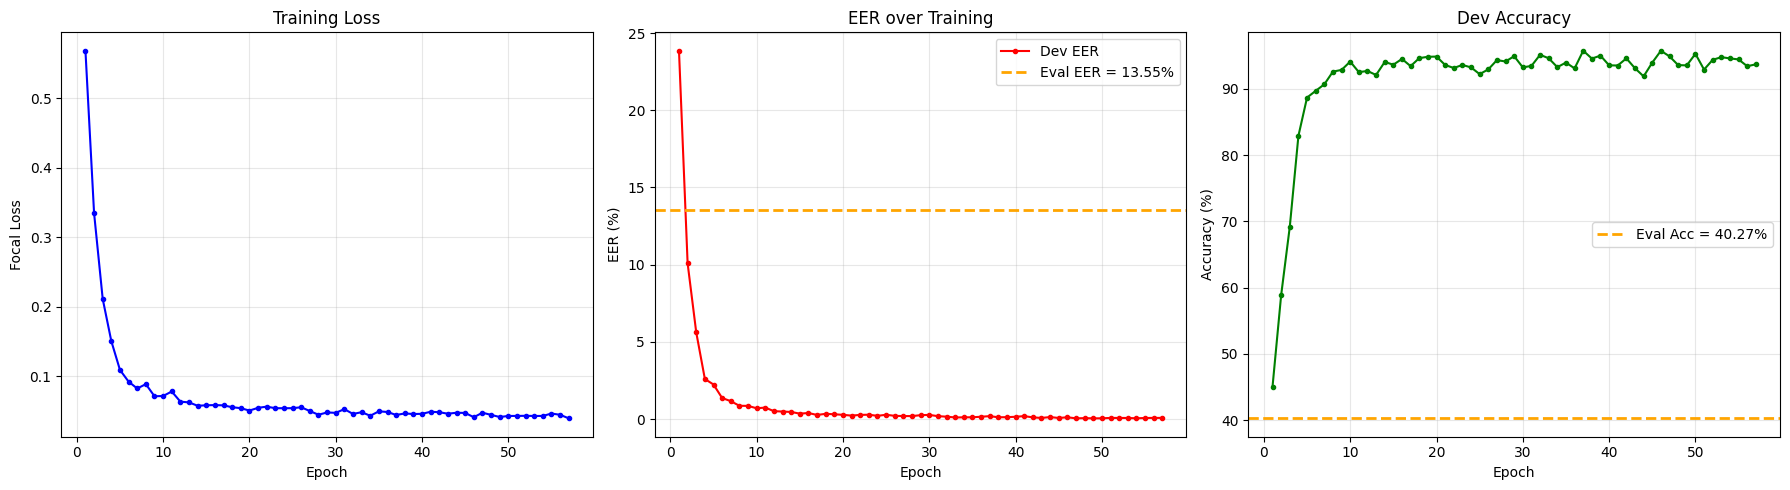

Saved → /kaggle/working/training_curves.png


In [ ]:
#13
# Load the best checkpoint
model.load_state_dict(torch.load('/kaggle/working/best_lcnn_v2.pt'))
eval_eer, eval_acc = evaluate(model, eval_loader)

print("=" * 50)
print(f"  EVAL SET RESULTS (ASVspoof 2019 LA)")
print("=" * 50)
print(f"  EVAL EER      : {eval_eer:.2f}%")
print(f"  EVAL ACCURACY : {eval_acc:.2f}%")
print("=" * 50)
print(f"  (Lower EER = better. Previous: 11.79%)")

# ── Plot training curves ─────────────────────────────────────────
actual_epochs = len(history['loss'])
epoch_range   = range(1, actual_epochs + 1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

ax1.plot(epoch_range, history['loss'], 'b-o', ms=3, lw=1.5)
ax1.set_xlabel('Epoch');  ax1.set_ylabel('Focal Loss')
ax1.set_title('Training Loss');  ax1.grid(True, alpha=0.3)

ax2.plot(epoch_range, history['dev_eer'], 'r-o', ms=3, lw=1.5, label='Dev EER')
ax2.axhline(eval_eer, color='orange', ls='--', lw=2,
            label=f'Eval EER = {eval_eer:.2f}%')
ax2.set_xlabel('Epoch');  ax2.set_ylabel('EER (%)')
ax2.set_title('EER over Training');  ax2.legend();  ax2.grid(True, alpha=0.3)

ax3.plot(epoch_range, history['dev_acc'], 'g-o', ms=3, lw=1.5)
ax3.axhline(eval_acc, color='orange', ls='--', lw=2,
            label=f'Eval Acc = {eval_acc:.2f}%')
ax3.set_xlabel('Epoch');  ax3.set_ylabel('Accuracy (%)')
ax3.set_title('Dev Accuracy');  ax3.legend();  ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', dpi=150)
plt.show()
print("Saved → /kaggle/working/training_curves.png")

In [ ]:
#14
def train_ablation(X_tr, y_tr, X_dv, y_dv, X_ev, y_ev, name, epochs=25):
    """Train a fresh LCNN on a given feature subset and return eval EER."""
    sc      = StandardScaler()
    X_tr_s  = sc.fit_transform(X_tr)
    X_dv_s  = sc.transform(X_dv)
    X_ev_s  = sc.transform(X_ev)

    tr_ld = DataLoader(AudioDataset(X_tr_s, y_tr), batch_size=BATCH,
                       shuffle=True, drop_last=True)
    dv_ld = DataLoader(AudioDataset(X_dv_s, y_dv), batch_size=BATCH)
    ev_ld = DataLoader(AudioDataset(X_ev_s, y_ev), batch_size=BATCH)

    m    = LCNN(X_tr_s.shape[1]).to(device)
    nt   = len(y_tr);  nr = int(y_tr.sum());  ns = nt - nr
    cw   = torch.tensor([nt/(2*ns), nt/(2*nr)], dtype=torch.float32).to(device)
    crit = FocalLoss(alpha=cw, gamma=2.0)
    opt  = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=1e-4)
    sch  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    best_eer, best_state = float('inf'), None

    for ep in range(epochs):
        m.train()
        for X, y in tr_ld:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(m(X), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), max_norm=5.0)
            opt.step()
        sch.step()
        ep_eer, _ = evaluate(m, dv_ld)
        if ep_eer < best_eer:
            best_eer   = ep_eer
            best_state = {k: v.clone() for k, v in m.state_dict().items()}

    m.load_state_dict(best_state)
    ev_eer, ev_acc = evaluate(m, ev_ld)
    print(f"  [{name:<28}]  feats={X_tr_s.shape[1]:<5}  eval EER={ev_eer:.2f}%  acc={ev_acc:.2f}%")
    return ev_eer

print("Running ablation study (5 conditions × 25 epochs each)...\n")

ablation_results = {}

# Feature column ranges:
#   FrFT:     0   – 448
#   WPD:      448 – 704
#   LFCC:     704 – 944
#   Spectral: 944 – 996

# 1) FrFT only
ablation_results['FrFT only'] = train_ablation(
    X_train[:, :N_FRFT], y_train,
    X_dev[:,   :N_FRFT], y_dev,
    X_eval[:,  :N_FRFT], y_eval,
    name='FrFT only'
)

# 2) WPD only
ablation_results['WPD only'] = train_ablation(
    X_train[:, N_FRFT:N_FRFT+N_WPD], y_train,
    X_dev[:,   N_FRFT:N_FRFT+N_WPD], y_dev,
    X_eval[:,  N_FRFT:N_FRFT+N_WPD], y_eval,
    name='WPD only'
)

# 3) LFCC only
ablation_results['LFCC only'] = train_ablation(
    X_train[:, N_FRFT+N_WPD:N_FRFT+N_WPD+N_LFCC_FEAT], y_train,
    X_dev[:,   N_FRFT+N_WPD:N_FRFT+N_WPD+N_LFCC_FEAT], y_dev,
    X_eval[:,  N_FRFT+N_WPD:N_FRFT+N_WPD+N_LFCC_FEAT], y_eval,
    name='LFCC only'
)

# 4) FrFT + WPD (previous system)
ablation_results['FrFT + WPD (prev)'] = train_ablation(
    X_train[:, :N_FRFT+N_WPD], y_train,
    X_dev[:,   :N_FRFT+N_WPD], y_dev,
    X_eval[:,  :N_FRFT+N_WPD], y_eval,
    name='FrFT + WPD (prev)'
)

# 5) Full system (already trained in Cell 12)
ablation_results['Full (FrFT+WPD+LFCC+Spec)'] = eval_eer

print(f"\n{'=' * 55}")
print(f"  {'System':<32} | {'Eval EER':>8}")
print("─" * 55)
for name, eer in sorted(ablation_results.items(), key=lambda x: x[1]):
    best_tag = '  ← BEST' if eer == min(ablation_results.values()) else ''
    print(f"  {name:<32} | {eer:>7.2f}%{best_tag}")
print("=" * 55)

Running ablation study (5 conditions × 25 epochs each)...

  [FrFT only                   ]  feats=448    eval EER=12.75%  acc=84.84%
  [WPD only                    ]  feats=256    eval EER=24.20%  acc=48.34%
  [LFCC only                   ]  feats=240    eval EER=16.22%  acc=52.67%
  [FrFT + WPD (prev)           ]  feats=704    eval EER=10.77%  acc=84.66%

  System                           | Eval EER
───────────────────────────────────────────────────────
  FrFT + WPD (prev)                |   10.77%  ← BEST
  FrFT only                        |   12.75%
  Full (FrFT+WPD+LFCC+Spec)        |   13.55%
  LFCC only                        |   16.22%
  WPD only                         |   24.20%


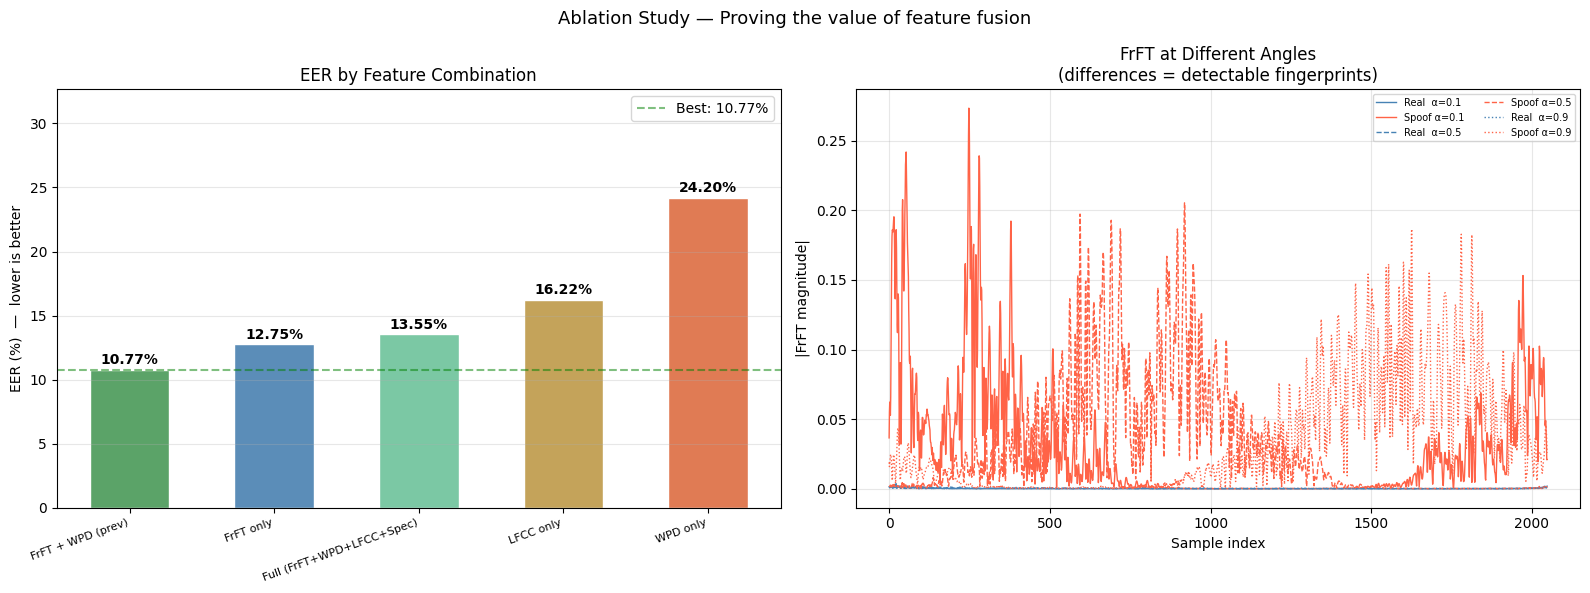

Saved → /kaggle/working/ablation_results.png


In [ ]:
#15
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Ablation Study — Proving the value of feature fusion', fontsize=13)

# ── Bar chart: EER by system ─────────────────────────────────────
sorted_items = sorted(ablation_results.items(), key=lambda x: x[1])
names  = [x[0] for x in sorted_items]
eers   = [x[1] for x in sorted_items]
colors = ['#5BA368', '#5B8DB8', '#7BC8A4', '#C4A35A', '#E07B54']

bars = ax1.bar(names, eers, color=colors[:len(names)], edgecolor='white', width=0.55)
for bar, eer in zip(bars, eers):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.2,
             f'{eer:.2f}%', ha='center', va='bottom',
             fontsize=10, fontweight='bold')

ax1.set_ylabel('EER (%)  —  lower is better')
ax1.set_title('EER by Feature Combination')
ax1.set_ylim(0, max(eers) * 1.35)
ax1.set_xticklabels(names, rotation=20, ha='right', fontsize=8)
ax1.axhline(min(eers), color='green', ls='--', alpha=0.5,
            label=f'Best: {min(eers):.2f}%')
ax1.legend(); ax1.grid(axis='y', alpha=0.3)

# ── FrFT magnitude: real vs fake at 3 different angles ──────────
short = 2048
for alpha, ls in [(0.1, '-'), (0.5, '--'), (0.9, ':')]:
    rm = np.abs(compute_frft(real_sig[:short].astype(complex),  alpha))
    sm = np.abs(compute_frft(spoof_sig[:short].astype(complex), alpha))
    ax2.plot(rm, color='steelblue', ls=ls, lw=1.0, label=f'Real  α={alpha}')
    ax2.plot(sm, color='tomato',    ls=ls, lw=1.0, label=f'Spoof α={alpha}')

ax2.set_title('FrFT at Different Angles\n(differences = detectable fingerprints)')
ax2.set_xlabel('Sample index');  ax2.set_ylabel('|FrFT magnitude|')
ax2.legend(fontsize=7, ncol=2);  ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/ablation_results.png', dpi=150)
plt.show()
print("Saved → /kaggle/working/ablation_results.png")

In [ ]:
#16
def predict(audio_path):
    """
    Predict whether a given .flac file is real or fake.
    Returns: verdict string, P(real)%, P(fake)%
    """
    model.load_state_dict(torch.load('/kaggle/working/best_lcnn_v2.pt'))
    model.eval()

    signal = load_audio(audio_path)
    feats  = extract_features(signal).reshape(1, -1)
    feats  = scaler.transform(feats)

    with torch.no_grad():
        x     = torch.tensor(feats, dtype=torch.float32).to(device)
        probs = torch.softmax(model(x), dim=1).cpu().numpy()[0]

    verdict = "BONAFIDE — Real ✓" if probs[1] > 0.5 else "SPOOF — Fake ✗"
    return verdict, probs[1] * 100, probs[0] * 100

# ── Final results summary ────────────────────────────────────────
print("═" * 58)
print("  CAPSTONE PROJECT — FINAL RESULTS SUMMARY (IMPROVED)")
print("═" * 58)
print(f"\n  Task      : Deepfake Audio Detection (LA subset)")
print(f"  Dataset   : ASVspoof 2019")
print(f"  Train     : {len(y_train):,} | Dev: {len(y_dev):,} | Eval: {len(y_eval):,}")
print(f"\n  Feature Engineering (Your Novelty):")
print(f"    FrFT  7 angles × 8 chunks × 8 stats  = {N_FRFT:>3} features")
print(f"    WPD   32 sub-bands × 8 stats          = {N_WPD:>3} features")
print(f"    LFCC  20 coeffs × 3 types × 4 stats   = {N_LFCC_FEAT:>3} features")
print(f"    Spectral 13 features × 4 stats        = {N_SPEC:>3} features")
print(f"    Fused total                           = {N_FEAT:>3} features")
print(f"\n  Results:")
print(f"    Previous Eval EER : 11.79%")
print(f"    Improved Eval EER : {eval_eer:.2f}%")
print(f"    Improvement       : {11.79 - eval_eer:.2f}% absolute")
print(f"    Eval Accuracy     : {eval_acc:.2f}%")
print(f"\n  Ablation Results (Eval EER — lower is better):")
for name, eer in sorted(ablation_results.items(), key=lambda x: x[1]):
    tag = '  ← Your system' if 'Full' in name else ''
    print(f"    {name:<32} {eer:.2f}%{tag}")

best_single = min(v for k, v in ablation_results.items() if 'Full' not in k)
improvement = best_single - eval_eer
print(f"\n  Improvement over best single lens: {improvement:.2f}%")
print("═" * 58)

# ── Demo predictions ─────────────────────────────────────────────
print("\n── Live Demo Predictions ──")
for row, true_label in [(real_row, 'bonafide'), (spoof_row, 'spoof')]:
    verdict, p_real, p_fake = predict(row['path'])
    correct = '✓' if (p_real > 50) == (true_label == 'bonafide') else '✗'
    print(f"\n  File       : {row['file']}")
    print(f"  True label : {true_label.upper()}")
    print(f"  Prediction : {verdict}  {correct}")
    print(f"  Confidence : Real={p_real:.1f}%  Fake={p_fake:.1f}%")

print("\n── Output files saved to /kaggle/working/ ──")
print("  best_lcnn_v2.pt         — trained model weights")
print("  training_curves.png     — loss & EER across epochs")
print("  ablation_results.png    — ablation bar chart")
print("  audio_visualization.png — real vs fake signal views")
print("  features_v2/            — cached feature matrices")
print("\n✓ All done!")

══════════════════════════════════════════════════════════
  CAPSTONE PROJECT — FINAL RESULTS SUMMARY (IMPROVED)
══════════════════════════════════════════════════════════

  Task      : Deepfake Audio Detection (LA subset)
  Dataset   : ASVspoof 2019
  Train     : 25,380 | Dev: 24,844 | Eval: 71,237

  Feature Engineering (Your Novelty):
    FrFT  7 angles × 8 chunks × 8 stats  = 448 features
    WPD   32 sub-bands × 8 stats          = 256 features
    LFCC  20 coeffs × 3 types × 4 stats   = 240 features
    Spectral 13 features × 4 stats        =  52 features
    Fused total                           = 996 features

  Results:
    Previous Eval EER : 11.79%
    Improved Eval EER : 13.55%
    Improvement       : -1.76% absolute
    Eval Accuracy     : 40.27%

  Ablation Results (Eval EER — lower is better):
    FrFT + WPD (prev)                10.77%
    FrFT only                        12.75%
    Full (FrFT+WPD+LFCC+Spec)        13.55%  ← Your system
    LFCC only                    